<a href="https://colab.research.google.com/github/Janith303/Sinhala-and-Maths-Model-training-/blob/DT/notebooks/DT_model_train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Import Library

In [8]:
import pandas as pd
from pathlib import Path
import joblib
from sklearn.model_selection import train_test_split, GridSearchCV
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, matthews_corrcoef, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve)

##LOAD AND PREPROCESS DATA

In [18]:
from google.colab import files

uploaded = files.upload()
FILE = list(uploaded.keys())[0]



Saving Maths operation data.xlsx to Maths operation data (1).xlsx


In [19]:
df = pd.read_excel(FILE)
print('Rows, columns:', df.shape)
df.head(10)

Rows, columns: (297, 7)


,No,Operation_Type,Total_Time,Carry_Over_Time,Erasure_Count,Hint_Requests,Student_Label
0,1,Addition,2.10,2.10,0,0,Normal
1,2,Addition,1.89,1.89,0,0,Normal
2,3,Addition,2.62,2.62,0,0,Normal
3,4,Addition,3.07,3.07,0,0,Normal
4,5,Division,8.20,8.20,0,0,Normal
5,6,Division,44.15,44.15,1,0,Normal
6,7,Division,34.86,34.86,0,0,Normal
7,8,Division,13.44,13.44,0,0,Normal
8,9,Subtraction,2.70,2.70,0,0,Normal
9,10,Subtraction,2.57,2.57,0,0,Normal


##Look at the data

In [5]:
print('Missing values:'); print(df.isna().sum().to_string())
print('\nClass counts:'); print(df['Student_Label'].value_counts())
print('\nAverages per class:')
df.groupby('Student_Label')[['Total_Time','Carry_Over_Time','Erasure_Count','Hint_Requests']].mean().round(2)

Missing values:
No                 0
Operation_Type     0
Total_Time         0
Carry_Over_Time    0
Erasure_Count      0
Hint_Requests      0
Student_Label      0

Class counts:
Student_Label
Normal    234
Slow       63
Name: count, dtype: int64

Averages per class:


,Total_Time,Carry_Over_Time,Erasure_Count,Hint_Requests
Student_Label,,,,
Normal,10.54,9.17,0.05,0.00
Slow,54.30,44.29,0.60,0.65


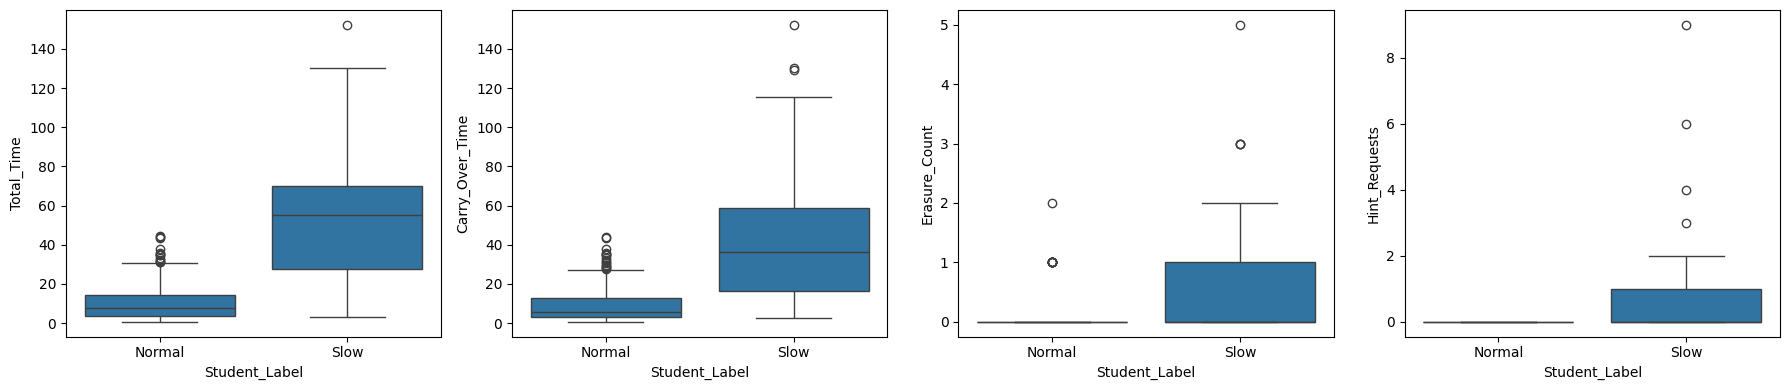

In [9]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, col in zip(ax, ['Total_Time','Carry_Over_Time','Erasure_Count','Hint_Requests']):
    sns.boxplot(data=df, x='Student_Label', y=col, ax=a)
plt.tight_layout(); plt.show()

##Feature engineering

In [22]:
USE_HINTS = True      # <- change to False and re-run to test without Hint_Requests

data = df.copy()
data['Slow'] = (data['Student_Label'] == 'Slow').astype(int)      # 1 = Slow, 0 = Normal
data['Carry_Ratio'] = data['Carry_Over_Time'] / data['Total_Time']
data['Non_Carry_Time'] = data['Total_Time'] - data['Carry_Over_Time']

num_cols = ['Total_Time', 'Carry_Over_Time', 'Erasure_Count', 'Carry_Ratio', 'Non_Carry_Time']
if USE_HINTS: num_cols.append('Hint_Requests')
cat_cols = ['Operation_Type']
FEATURES = num_cols + cat_cols

X = data[FEATURES]
y = data['Slow']
print('Features used:', FEATURES)

Features used: ['Total_Time', 'Carry_Over_Time', 'Erasure_Count', 'Carry_Ratio', 'Non_Carry_Time', 'Hint_Requests', 'Operation_Type']


##Split into train (80%) and test (20%)

In [24]:
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train rows:', len(X_train), '| Test rows:', len(X_test))
print('Slow share  train:', round(y_train.mean(), 3), ' test:', round(y_test.mean(), 3))

Train rows: 237 | Test rows: 60
Slow share  train: 0.211  test: 0.217
